In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import awareness as A, features as F, plots as P, stats as S
from aqs.config import CITIES, PROCESSED

pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 100)
P.use_theme()
long = F.load_long()

In [2]:
table = S.correlation_table(long)
table.to_csv(PROCESSED / "results_summary.csv", index=False)
table

,city,series,role,weeks,raw_r,raw_spearman,deseason_r,ci_low,ci_high,p_shift,peak_lag,term,geo_level,zero_share,p_fdr,significant
0,bangkok,attention index (PC1),attention,150,0.702,0.819,0.528,0.370,0.660,0.007,0,NaN,NaN,NaN,0.020,True
1,bangkok,"air purifier (English, country)",protection,150,0.575,0.730,0.327,0.114,0.557,0.007,0,air_purifier,country,0.000,0.020,True
2,bangkok,"air quality (English, country)",awareness,150,0.653,0.770,0.549,0.392,0.684,0.007,0,air_quality,country,0.007,0.020,True
3,bangkok,breathing difficulty (Thai),health,150,0.051,-0.028,-0.011,-0.181,0.170,0.930,-5,breathing_difficulty_th,country,0.013,0.930,False
4,bangkok,"chest pain (English, country)",health,150,-0.069,-0.084,-0.057,-0.188,0.070,0.542,6,chest_pain,country,0.000,0.671,False
5,bangkok,chest pain (Thai),health,150,0.226,0.211,0.130,-0.050,0.240,0.197,0,chest_pain_th,country,0.000,0.354,False
6,bangkok,cough medicine (Thai),health,150,0.081,0.086,0.128,-0.091,0.291,0.275,-3,cough_medicine_th,country,0.000,0.461,False
7,bangkok,"eye drops (English, country)",health,150,-0.083,-0.122,0.119,0.005,0.250,0.232,0,eye_drops,country,0.000,0.403,False
8,bangkok,eye drops (Thai),health,150,0.052,0.045,0.205,0.068,0.357,0.092,-1,eye_drops_th,country,0.000,0.227,False
9,bangkok,"hospital (English, country)",health,150,-0.007,0.007,-0.168,-0.301,-0.055,0.190,<NA>,hospital,country,0.000,0.353,False


In [3]:
table.groupby(["city", "role"], sort=False).agg(
    series=("series", "size"), median_raw_r=("raw_r", "median"), median_deseason_r=("deseason_r", "median"),
    significant=("significant", "sum"))

series  median_raw_r  median_deseason_r  significant
city      role                                                            
bangkok   attention        1         0.702              0.528            1
          protection       3         0.604              0.381            3
          awareness        5         0.659              0.549            5
          health           8         0.022              0.054            0
krakow    attention        1         0.745              0.582            1
          protection       2         0.629              0.373            2
          awareness        2         0.674              0.532            2
          health           8         0.056              0.054            0
melbourne attention        1        -0.063              0.070            0
          protection       4        -0.012              0.099            0
          awareness        2         0.204              0.219            0
          health           5         0.154             -0.022            0
lahore    attention        1         0.569              0.587            1
          protection       2         0.321              0.405            1
          awareness        2         0.601              0.580            2
          health           5        -0.045              0.094            0

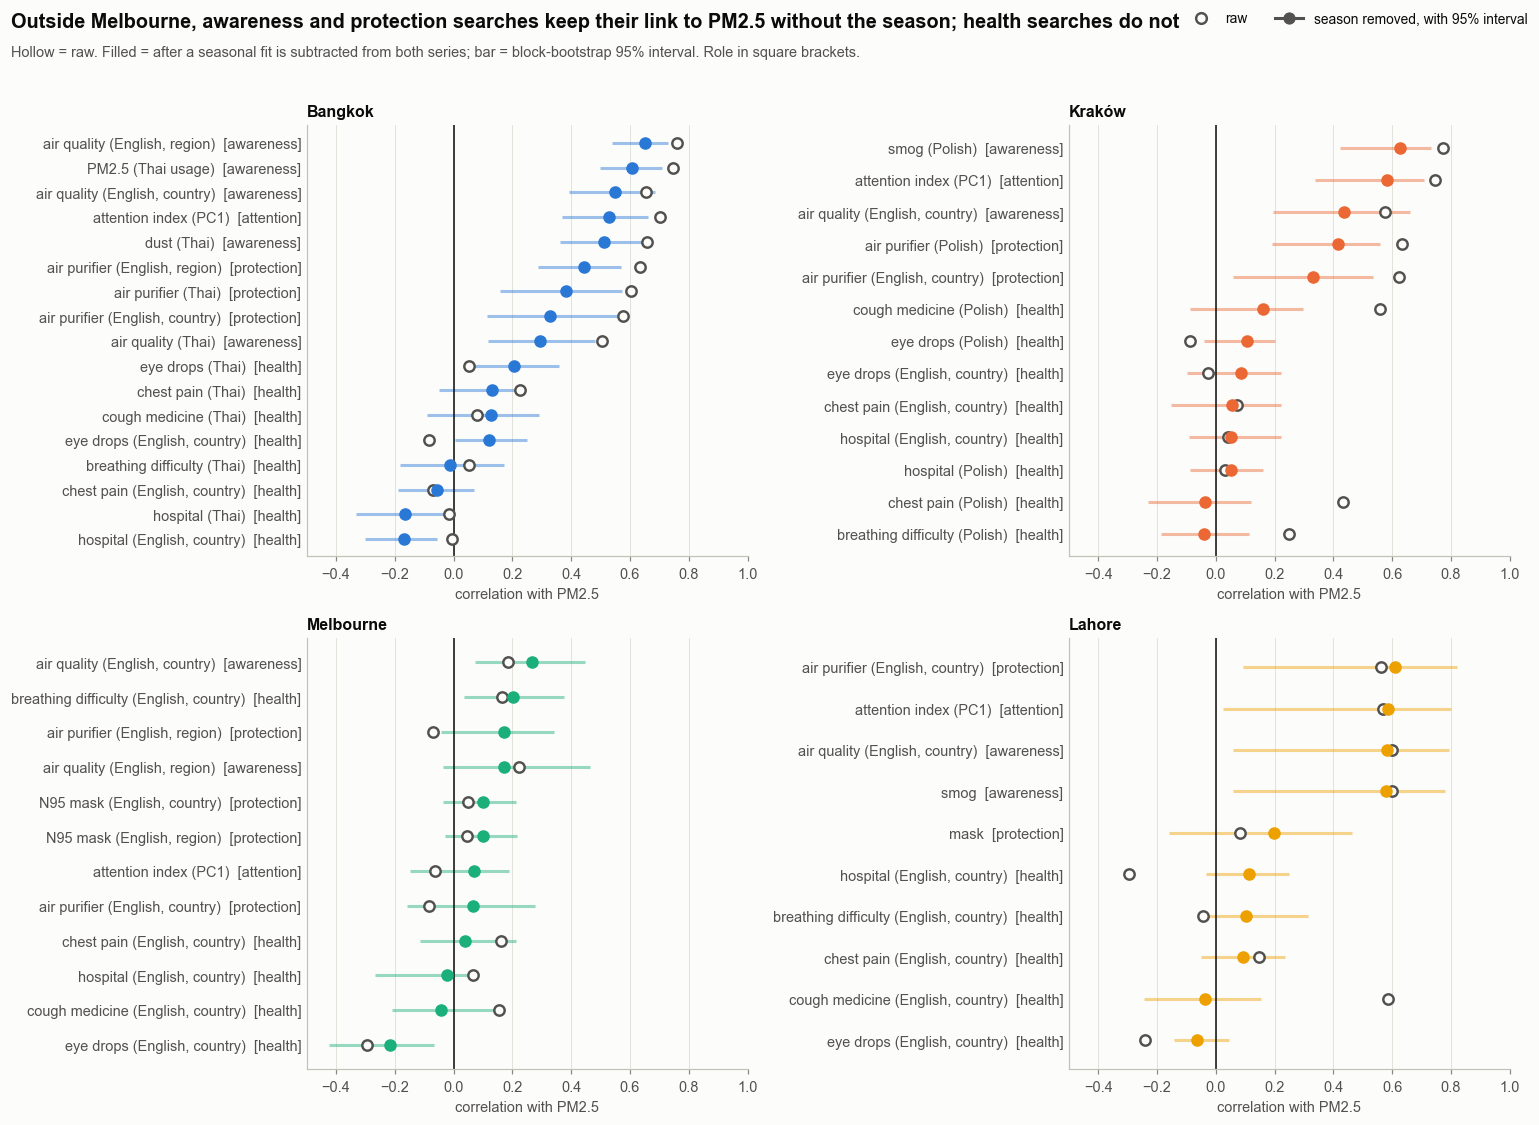

In [4]:
P.raw_vs_deseasonalized(table);

In [5]:
table.pivot_table(index="city", columns="role", values="peak_lag", aggfunc=lambda s: s.notna().sum(), sort=False).join(
    table.groupby("city", sort=False).size().rename("series"))

,attention,protection,awareness,health,series
city,,,,,
bangkok,1,3,5,6,17
krakow,1,2,2,5,13
melbourne,1,3,0,5,12
lahore,1,2,2,4,10


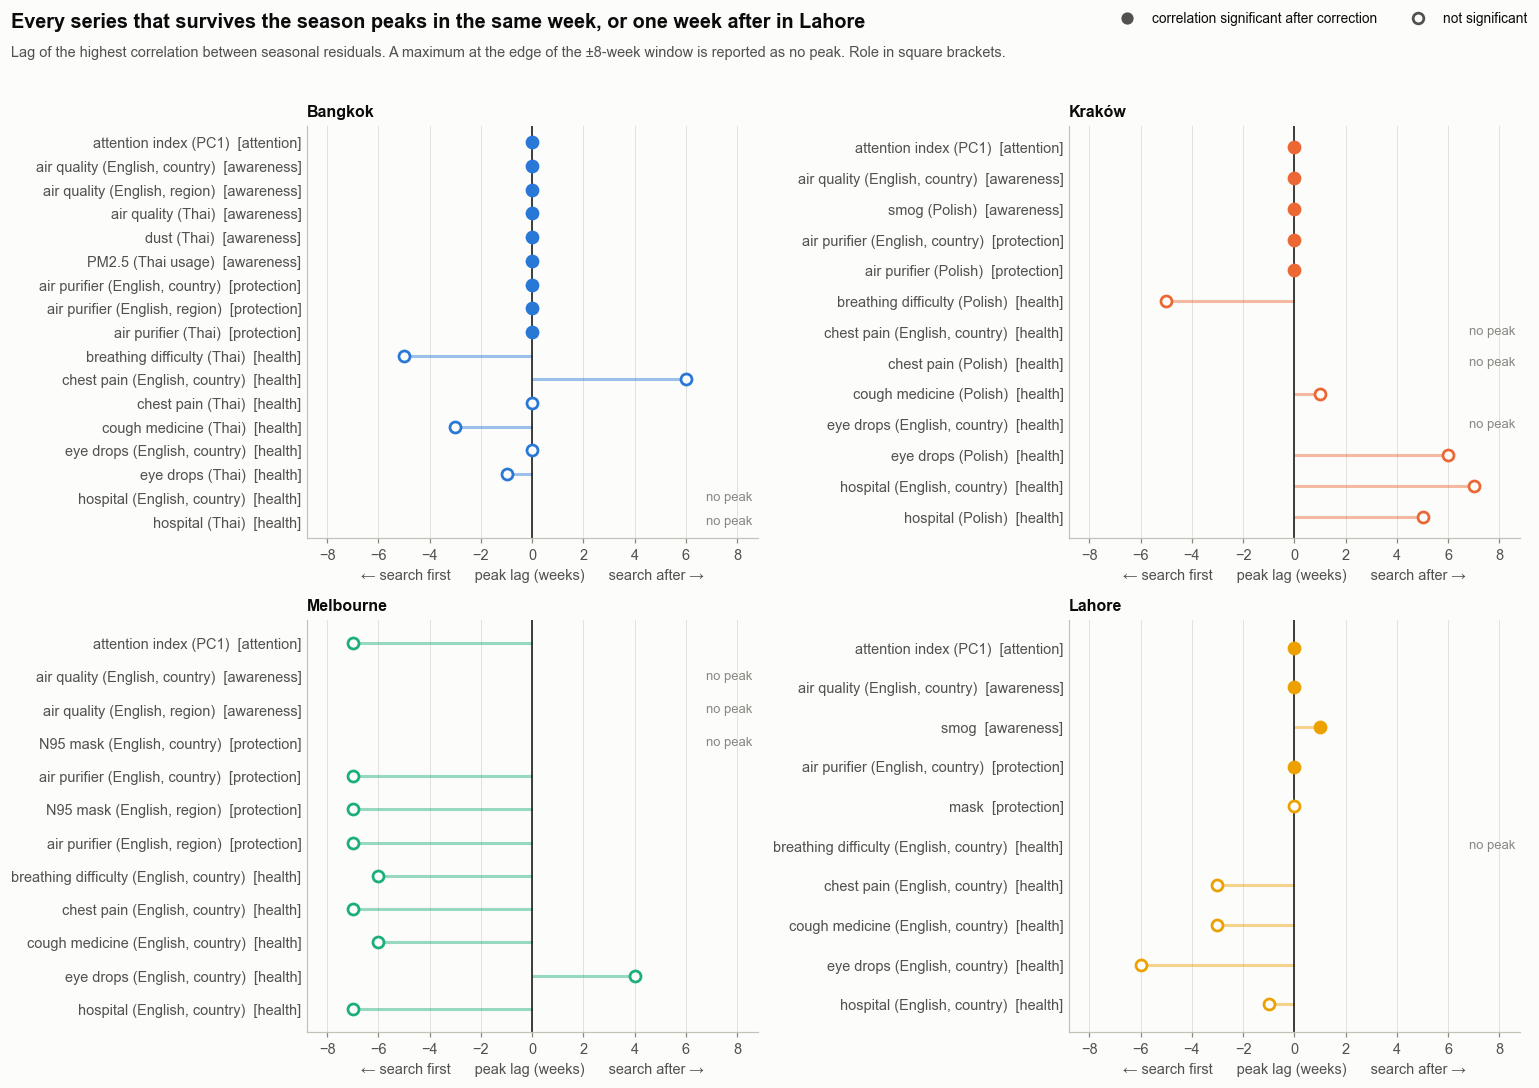

In [6]:
P.term_lag_comparison(table);

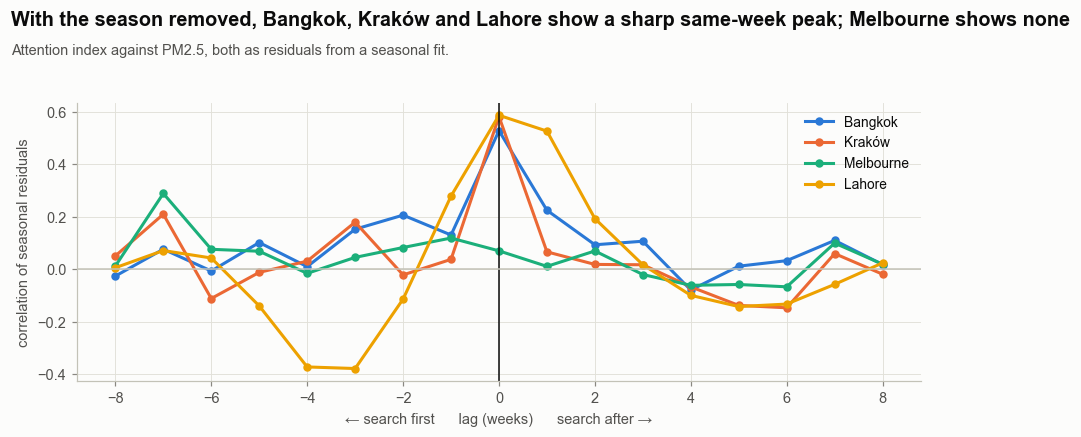

In [7]:
P.deseasonalized_lags(long);

In [8]:
pd.concat({role: pd.DataFrame({c: S.tertile_test(F.role_pair(long, c, role)) for c in CITIES}).T
           for role in ["attention", "health"]})

H          p  epsilon_sq  median_low  median_mid  \
attention bangkok    87.092  1.225e-19       0.579      -0.631      -0.302   
          krakow     64.565  9.547e-15       0.478      -0.688      -0.409   
          melbourne   0.079  9.613e-01      -0.021      -0.219      -0.165   
          lahore     38.348  4.708e-09       0.303      -0.333      -0.307   
health    bangkok     0.731  6.940e-01      -0.009      -0.128      -0.128   
          krakow     12.672  1.771e-03       0.081      -0.348       0.098   
          melbourne   2.479  2.896e-01       0.005      -0.213      -0.240   
          lahore      0.099  9.516e-01      -0.016       0.390       0.322   

                     median_high  
attention bangkok          0.256  
          krakow           0.723  
          melbourne       -0.177  
          lahore          -0.010  
health    bangkok         -0.193  
          krakow           0.407  
          melbourne        0.235  
          lahore           0.288